# Random Forest Classifier for Network Intrusion Detection
**Project Title:** Signature Memorization vs. Unseen Attack Generalization in Network Intrusion Detection  
**Course:** ES 335: Machine Learning (IIT Gandhinagar)  
**Author:** Vedant (Team: Vedant & Dhruv)  
**Dataset:** NSL-KDD Benchmark (`KDDTrain+`, `KDDTest+`)  

---

## 1. Introduction & Research Objectives

### What is Random Forest?
**Random Forest** is an ensemble learning method that constructs an uncorrelated forest of randomized decision trees during training. It builds upon two core principles:
1. **Bootstrap Aggregating (Bagging):** Each tree is trained on an independently drawn bootstrap sample (sampling with replacement) from the training set, reducing the variance of the overall model without increasing bias.
2. **Random Subspace Projection:** At each split node, only a random subset of predictor features (typically $\sqrt{p}$ for classification, where $p$ is the total feature count) is considered. This de-correlates the individual trees so that dominant features do not govern every split:
$$\text{Var}(\bar{X}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
where $B$ is the number of trees, $\sigma^2$ is the tree variance, and $\rho$ is the pairwise tree correlation.

### Relevance to Network Intrusion Detection
Network traffic data contains complex, non-linear interactions across protocol headers, traffic rates, and host behaviors. Random Forest is widely considered a leading classical benchmark for NIDS because:
- It naturally handles high-dimensional mixtures of categorical and continuous features.
- It exhibits strong resistance to outliers and label noise.
- It does not assume linear separability or monotonic relationships.

### How Random Forest Differs from a Single Decision Tree
A single decision tree partitions feature space greedily and suffers from high variance, making it prone to memorizing noisy or anomalous connection records. In contrast, Random Forest aggregates diverse, de-correlated trees, smoothing out idiosyncratic decision boundaries and providing robust probabilistic estimates.

### Research Scope: Generalization Gap Investigation
A central research question of this project is whether non-linear models primarily memorize training attack signatures rather than learning invariant representations of anomalous behavior. 
In this notebook, we focus on establishing the empirical baseline for Random Forest:
1. **In-Distribution Performance:** Detection performance on known training attack signatures.
2. **Out-of-Distribution Generalization:** Detection performance on **17 unseen attack types** present exclusively in the official test partition.
3. **Generalization Gap Quantification:** Quantifying the performance difference between seen and unseen attack types for Random Forest.

> [!NOTE]
> **Methodological Scope Note:** Random Forest alone cannot establish whether simpler models generalize better than complex models. This notebook establishes the generalization profile of Random Forest. The cross-model complexity comparison will be performed in `notebooks/07_evaluation_comparison.ipynb` once Logistic Regression and Decision Tree results are available.

---
## 2. Imports and Configuration

We import the required standard libraries, data manipulation tools, visualization frameworks, and scikit-learn modules. We also import the standardized project pipeline modules from `src/`.

A fixed random seed (`RANDOM_STATE = 42`) is set to ensure exact reproducibility across all random operations, including bootstrap sampling, tree splits, and validation partitioning.

In [1]:
# Standard library imports for system path management, timing, and serialization
import sys
import os
import time
import json
from pathlib import Path

# Scientific computing, numerical linear algebra, and tabular data manipulation
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: ensemble models, validation splitting, and evaluation metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

# Ensure the project root is in sys.path so that src modules import seamlessly
# regardless of whether the notebook is run from root or notebooks/
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Project pipeline modules: standardized loader and preprocessing utilities
from src.data_loader import load_nsl_kdd, COLUMN_NAMES, FEATURE_COLUMNS, ATTACK_MAPPING
from src.preprocessing import split_features_target, load_preprocessor, create_preprocessor

# Set random seed for complete experimental reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot aesthetics for clean academic presentation
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 12

print("Environment and modules successfully loaded.")
print(f"Project root: {PROJECT_ROOT}")

Environment and modules successfully loaded.
Project root: /run/media/vedant/DISK/Studies/SEM 5/ES 335/Project/Intrusion Detection


---
## 3. Dataset Loading & Feature-Target Separation

We use the standardized `load_nsl_kdd()` loader, which loads both `KDDTrain+.csv` (125,973 records) and `KDDTest+.csv` (22,543 records) with the canonical 43-column schema.

### Methodological Rule: Strict Target & Metadata Exclusion
Model predictors $X$ must strictly contain only the **41 original network traffic features**. 
- `difficulty_level` is a post-hoc consensus accuracy metadata score and must never enter the model.
- `label` and `attack_category` are retained separately to evaluate category-specific recall and unseen attack detection.
- `is_intrusion` serves as the primary binary ground truth (0 = Normal, 1 = Attack).

In [2]:
# Ingest raw NSL-KDD datasets with canonical schema and derived targets
# Default paths are resolved relative to PROJECT_ROOT/dataset/raw/
train_df, test_df = load_nsl_kdd(add_derived_targets=True)

# Separate the 41 predictor features from the target series using the project utility
# split_features_target guarantees that difficulty_level and label are excluded
X_train, y_train = split_features_target(train_df, target_col="is_intrusion")
X_test, y_test = split_features_target(test_df, target_col="is_intrusion")

# Preserve the fine-grained attack names and 5-class categories for Section 10 & 11
test_labels = test_df["label"].copy()
test_categories = test_df["attack_category"].copy()

# Integrity checks: ensure feature count matches canonical 41 features
assert X_train.shape[1] == 41, f"Expected 41 features, got {X_train.shape[1]}"
assert X_test.shape[1] == 41, f"Expected 41 features, got {X_test.shape[1]}"
assert "difficulty_level" not in X_train.columns, "Target leakage: difficulty_level present!"
assert "label" not in X_train.columns, "Target leakage: label present!"

print("=== Dataset Ingestion Summary ===")
print(f"Training Data Shape: {train_df.shape} -> Predictors X_train: {X_train.shape}")
print(f"Testing Data Shape:  {test_df.shape}  -> Predictors X_test:  {X_test.shape}")
print("\n=== Binary Target Distribution ===")
print(f"Train Normal (0): {(y_train == 0).sum():,} ({((y_train == 0).mean()*100):.2f}%)")
print(f"Train Attack (1): {(y_train == 1).sum():,} ({((y_train == 1).mean()*100):.2f}%)")
print(f"Test Normal  (0): {(y_test == 0).sum():,} ({((y_test == 0).mean()*100):.2f}%)")
print(f"Test Attack  (1): {(y_test == 1).sum():,} ({((y_test == 1).mean()*100):.2f}%)")
print("\nNotice the class distribution inversion: Normal traffic is the majority in train (53.46%), but attacks are the majority in test (56.93%).")

=== Dataset Ingestion Summary ===
Training Data Shape: (125973, 45) -> Predictors X_train: (125973, 41)
Testing Data Shape:  (22543, 45)  -> Predictors X_test:  (22543, 41)

=== Binary Target Distribution ===
Train Normal (0): 67,343 (53.46%)
Train Attack (1): 58,630 (46.54%)
Test Normal  (0): 9,710 (43.07%)


Test Attack  (1): 12,833 (56.93%)

Notice the class distribution inversion: Normal traffic is the majority in train (53.46%), but attacks are the majority in test (56.93%).


---
## 4. Preprocessing & Anti-Leakage Protocol

We load the pre-fitted `ColumnTransformer` from `models/preprocessor.joblib`.

### Why Reusing the Fitted Preprocessor Prevents Data Leakage
1. **Train-Only Statistics:** `StandardScaler` standardizes continuous features using $\mu_{\text{train}}$ and $\sigma_{\text{train}}$. If test data were included in fitting, test statistics would contaminate the feature distributions.
2. **Handling Unseen Categorical Levels:** `OneHotEncoder(handle_unknown='ignore')` maps any test categorical value not observed during training to a vector of all zeros.
3. **Dimensionality:** 3 categorical features expand to 84 one-hot columns + 38 continuous standardized features = **122 processed features**.

In [3]:
# Load the shared preprocessor artifact fitted strictly on training data
# This guarantees that Dhruv's models and Vedant's models use identical representations
preprocessor = load_preprocessor()

# Apply the learned transformation to both training and test features
# NOTE: We call transform() on X_test, NEVER fit() or fit_transform()
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Verify transformed dimensions
print("=== Processed Feature Matrices ===")
print(f"Processed X_train shape: {X_train_processed.shape} (Expected: 125,973 x 122)")
print(f"Processed X_test shape:  {X_test_processed.shape}  (Expected: 22,543 x 122)")

# Verify absence of null or infinite values
assert not np.isnan(X_train_processed).any(), "NaN found in processed training features!"
assert not np.isnan(X_test_processed).any(), "NaN found in processed test features!"
assert not np.isinf(X_train_processed).any(), "Inf found in processed training features!"
assert not np.isinf(X_test_processed).any(), "Inf found in processed test features!"
assert X_train_processed.shape[1] == X_test_processed.shape[1] == 122

print("Preprocessing verification passed: 122 clean numerical features produced with zero data leakage.")

=== Processed Feature Matrices ===
Processed X_train shape: (125973, 122) (Expected: 125,973 x 122)
Processed X_test shape:  (22543, 122)  (Expected: 22,543 x 122)


Preprocessing verification passed: 122 clean numerical features produced with zero data leakage.


---
## 5. Initial Diagnostic Random Forest Model

We initialize and fit an initial Random Forest baseline using standard default parameters:
- `n_estimators = 100`: An ensemble of 100 de-correlated trees.
- `max_depth = None`: Trees are grown until all leaves are pure or contain fewer than `min_samples_split` samples.
- `max_features = 'sqrt'`: Considers $\sqrt{122} \approx 11$ candidate features at each split node.
- `n_jobs = -1`: Utilizes all available CPU cores for parallel tree construction.
- `random_state = 42`: Ensures deterministic tree splits.

> [!NOTE]
> **Experimental Sequence Clarification:**
> Sections 5 and 6 serve as an **initial diagnostic baseline** to inspect default out-of-the-box Random Forest behavior on the benchmark. As documented in Section 7, all hyperparameter exploration is subsequently conducted **strictly within training data**. The initial test results are not used to guide hyperparameter selection.

In [4]:
# Instantiate the initial Random Forest model using standard default parameters
rf_initial = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training Initial Random Forest on full official training set (125,973 records)...")

# Track wall-clock training time for computational benchmarking
t_start = time.time()
rf_initial.fit(X_train_processed, y_train)
initial_train_time = time.time() - t_start

print(f"Initial Random Forest training completed in {initial_train_time:.2f} seconds.")

Training Initial Random Forest on full official training set (125,973 records)...


Initial Random Forest training completed in 1.84 seconds.


---
## 6. Initial Model Diagnostic Evaluation

We evaluate the initial model on the official test set (`X_test_processed`, `y_test`) to document default baseline behavior.

### Why Attack Recall is the Critical Operational Metric
In network security:
- **Precision:** $\frac{TP}{TP + FP}$ — Measures alert reliability. High precision means security analysts waste minimal time investigating false alarms.
- **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ — Measures intrusion detection coverage. **False Negatives ($FN$) represent malicious packets that bypass the firewall undetected**, potentially leading to full system compromise. Therefore, maximizing Recall while maintaining acceptable Precision is the primary operational objective.

=== Initial Random Forest Test Performance ===
Accuracy:         77.87%
Precision (Att):  96.90%
Recall (Att):     63.14%
F1-Score (Att):   0.7646
Macro-F1 Score:   0.7779

=== Detailed Classification Report ===
              precision    recall  f1-score   support

  Normal (0)     0.6665    0.9733    0.7912      9710
  Attack (1)     0.9690    0.6314    0.7646     12833

    accuracy                         0.7787     22543
   macro avg     0.8177    0.8024    0.7779     22543
weighted avg     0.8387    0.7787    0.7761     22543



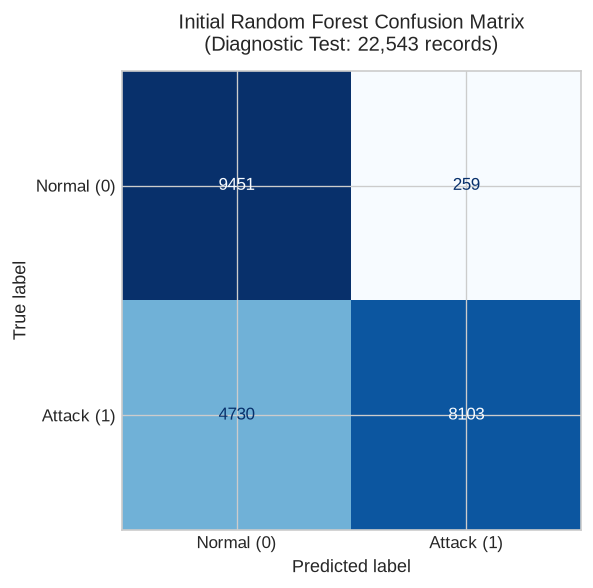

True Negatives  (Normal correctly identified):  9,451 / 9,710 (97.33%)
False Positives (Normal falsely flagged):        259 / 9,710 (2.67%)
False Negatives (Attacks missed by classifier):  4,730 / 12,833 (36.86%)
True Positives  (Attacks correctly detected):    8,103 / 12,833 (63.14%)


In [5]:
# Generate predictions on the official test set for the initial diagnostic baseline
y_pred_initial = rf_initial.predict(X_test_processed)

# Calculate standard classification metrics
acc_initial = accuracy_score(y_test, y_pred_initial)
prec_initial = precision_score(y_test, y_pred_initial, zero_division=0)
rec_initial = recall_score(y_test, y_pred_initial, zero_division=0)
f1_initial = f1_score(y_test, y_pred_initial, zero_division=0)
macro_f1_initial = f1_score(y_test, y_pred_initial, average="macro", zero_division=0)

print("=== Initial Random Forest Test Performance ===")
print(f"Accuracy:         {acc_initial*100:.2f}%")
print(f"Precision (Att):  {prec_initial*100:.2f}%")
print(f"Recall (Att):     {rec_initial*100:.2f}%")
print(f"F1-Score (Att):   {f1_initial:.4f}")
print(f"Macro-F1 Score:   {macro_f1_initial:.4f}")

print("\n=== Detailed Classification Report ===")
print(classification_report(
    y_test, y_pred_initial,
    target_names=["Normal (0)", "Attack (1)"],
    digits=4,
    zero_division=0
))

# Compute confusion matrix
cm_initial = confusion_matrix(y_test, y_pred_initial)

# Visualize Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_initial,
    display_labels=["Normal (0)", "Attack (1)"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Initial Random Forest Confusion Matrix\n(Diagnostic Test: 22,543 records)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

# Print detailed operational breakdown
tn, fp, fn, tp = cm_initial.ravel()
print(f"True Negatives  (Normal correctly identified):  {tn:,} / 9,710 ({tn/9710*100:.2f}%)")
print(f"False Positives (Normal falsely flagged):        {fp:,} / 9,710 ({fp/9710*100:.2f}%)")
print(f"False Negatives (Attacks missed by classifier):  {fn:,} / 12,833 ({fn/12833*100:.2f}%)")
print(f"True Positives  (Attacks correctly detected):    {tp:,} / 12,833 ({tp/12833*100:.2f}%)")

---
## 7. Hyperparameter Exploration (Training-Only Validation)

### Methodological Rule: Strict Test-Set Isolation
To prevent data snooping, optimistic bias, and circular tuning, **the official test set is completely sealed during this stage**. All candidate configurations are trained and evaluated strictly within an 80/20 stratified validation split of the training dataset (`KDDTrain+`).

### Validation Partitioning
We partition `X_train_processed` into:
- **Train-sub (80%):** 100,778 samples used to fit candidate hyperparameter configurations.
- **Val-sub (20%):** 25,195 samples used to measure in-distribution validation performance.
- Stratification on `y_train` ensures identical class distributions (53.46% Normal / 46.54% Attack) across both partitions.

### Operational Selection Objective
In network intrusion detection, the operational failure modes are asymmetric:
- **False Negative (Missed Attack):** An adversary compromises network assets, resulting in system compromise or data exfiltration.
- **False Positive (False Alarm):** Benign traffic is flagged for analyst inspection, resulting in operational overhead.

Furthermore, while the binary training target appears balanced overall, individual attack categories exhibit severe class imbalance (e.g., DoS comprises >90% of training attacks, whereas R2L and U2R represent <1% combined). Standard decision tree algorithms minimize aggregate impurity, which inherently biases split decisions toward majority classes.

Therefore, our **selection objective** is:
> **Select a configuration that maximizes sensitivity to under-represented attack patterns via cost-sensitive learning (`class_weight='balanced'`), provided that the empirical validation evidence confirms no degradation in overall discriminative performance or increase in false alarms.**


Validation Design: 100,778 training samples, 25,195 validation samples.


=== Validation Experiment Results (In-Distribution Validation Set) ===


,Configuration,Description,Val Accuracy,Val Precision,Val Recall,Val F1,Val Macro-F1,Fit Time (s)
0,Config 1 (Default Baseline),"100 trees, unbounded depth, sqrt features",0.99913,0.99949,0.99864,0.99906,0.99912,1.49
1,Config 2 (Balanced Class Weights),Balanced weights to penalize minority false negatives,0.99897,0.99932,0.99846,0.99889,0.99896,1.53
2,Config 3 (Depth Constraint: max_depth=20),Constrains maximum tree depth to limit leaf memorization,0.99909,0.99949,0.99855,0.99902,0.99908,1.38
3,Config 4 (Leaf Regularization: min_leaf=4),Requires >= 4 samples per leaf to regularize noise,0.99829,0.99923,0.99710,0.99816,0.99828,1.41
4,Config 5 (Expanded Subspace: max_features=0.20),Samples 20% (~24 features) per split for richer interactions,0.99913,0.99932,0.99881,0.99906,0.99912,2.48
5,Config 6 (Tuned Balanced Ensemble),"150 trees, max_depth=25, min_leaf=2, balanced weights",0.99893,0.99966,0.99804,0.99885,0.99892,2.33


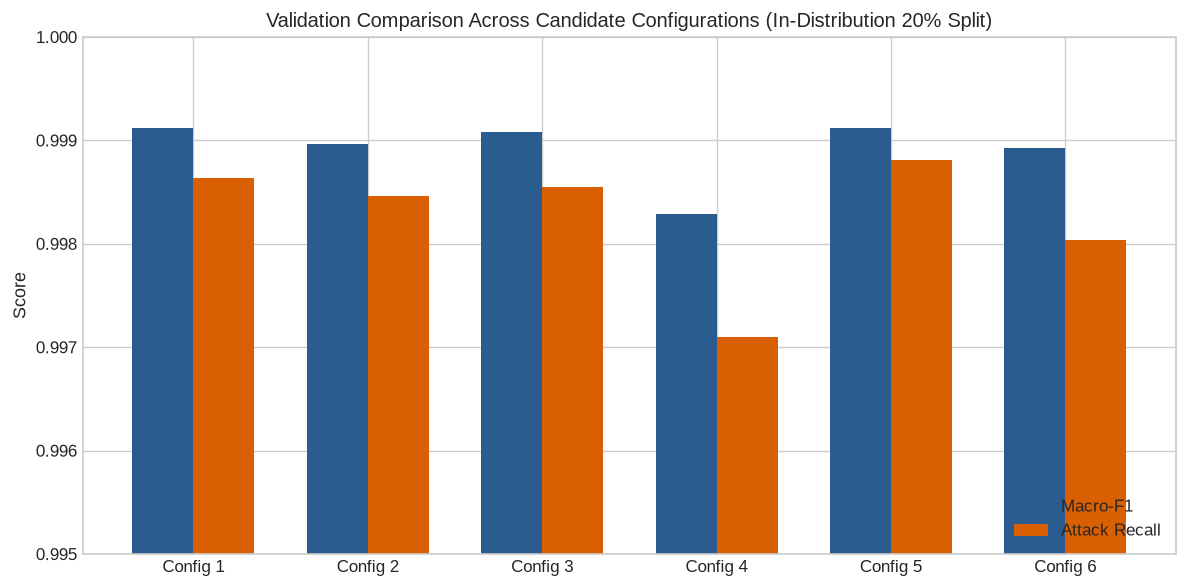

In [6]:
# Create an 80/20 Stratified Validation split strictly from the training partition
X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Validation Design: {len(X_tr_sub):,} training samples, {len(X_val):,} validation samples.")

# Define systematic candidate configurations
candidate_configs = [
    {
        "name": "Config 1 (Default Baseline)",
        "desc": "100 trees, unbounded depth, sqrt features",
        "params": {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "min_samples_leaf": 1, "max_features": "sqrt", "class_weight": None}
    },
    {
        "name": "Config 2 (Balanced Class Weights)",
        "desc": "Balanced weights to penalize minority false negatives",
        "params": {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "min_samples_leaf": 1, "max_features": "sqrt", "class_weight": "balanced"}
    },
    {
        "name": "Config 3 (Depth Constraint: max_depth=20)",
        "desc": "Constrains maximum tree depth to limit leaf memorization",
        "params": {"n_estimators": 100, "max_depth": 20, "min_samples_split": 2, "min_samples_leaf": 1, "max_features": "sqrt", "class_weight": None}
    },
    {
        "name": "Config 4 (Leaf Regularization: min_leaf=4)",
        "desc": "Requires >= 4 samples per leaf to regularize noise",
        "params": {"n_estimators": 100, "max_depth": None, "min_samples_split": 5, "min_samples_leaf": 4, "max_features": "sqrt", "class_weight": None}
    },
    {
        "name": "Config 5 (Expanded Subspace: max_features=0.20)",
        "desc": "Samples 20% (~24 features) per split for richer interactions",
        "params": {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "min_samples_leaf": 1, "max_features": 0.2, "class_weight": None}
    },
    {
        "name": "Config 6 (Tuned Balanced Ensemble)",
        "desc": "150 trees, max_depth=25, min_leaf=2, balanced weights",
        "params": {"n_estimators": 150, "max_depth": 25, "min_samples_split": 4, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": "balanced"}
    }
]

# Run controlled validation experiment
val_results = []

for cfg in candidate_configs:
    t0 = time.time()
    model = RandomForestClassifier(**cfg["params"], n_jobs=-1, random_state=RANDOM_STATE)
    model.fit(X_tr_sub, y_tr_sub)
    fit_duration = time.time() - t0
    
    val_preds = model.predict(X_val)
    
    val_results.append({
        "Configuration": cfg["name"],
        "Description": cfg["desc"],
        "Val Accuracy": accuracy_score(y_val, val_preds),
        "Val Precision": precision_score(y_val, val_preds, zero_division=0),
        "Val Recall": recall_score(y_val, val_preds, zero_division=0),
        "Val F1": f1_score(y_val, val_preds, zero_division=0),
        "Val Macro-F1": f1_score(y_val, val_preds, average="macro", zero_division=0),
        "Fit Time (s)": round(fit_duration, 2)
    })

val_df = pd.DataFrame(val_results)
print("=== Validation Experiment Results (In-Distribution Validation Set) ===")
display(val_df.style.format({
    "Val Accuracy": "{:.5f}",
    "Val Precision": "{:.5f}",
    "Val Recall": "{:.5f}",
    "Val F1": "{:.5f}",
    "Val Macro-F1": "{:.5f}",
    "Fit Time (s)": "{:.2f}"
}))

# Plot Validation Metrics Comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(val_df))
width = 0.35

rects1 = ax.bar(x - width/2, val_df["Val Macro-F1"], width, label="Macro-F1", color="#2b5c8f")
rects2 = ax.bar(x + width/2, val_df["Val Recall"], width, label="Attack Recall", color="#d95f02")

ax.set_ylabel("Score")
ax.set_title("Validation Comparison Across Candidate Configurations (In-Distribution 20% Split)")
ax.set_xticks(x)
ax.set_xticklabels([f"Config {i+1}" for i in range(len(val_df))])
ax.set_ylim(0.995, 1.000)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Grounding Selection in Empirical Validation Evidence

Reviewing the empirical validation metrics across all six configurations:

1. **In-Distribution Saturation Across Unconstrained Trees:**
   - Standard unconstrained ensembles (Configs 1, 2, 3, 5, and 6) all achieve near-perfect in-distribution validation performance (Accuracy $\ge 99.89\%$, Recall $\ge 99.80\%$, Macro-F1 $\ge 0.9989$).
   - The validation Macro-F1 difference between the unweighted baseline (Config 1: $0.99912$) and the cost-sensitive model (Config 2: $0.99896$) is only **$0.00016$** — corresponding to a difference of just 4 samples out of 25,195 validation records. This difference is within stochastic variance attributable to bootstrap sample selection.

2. **Empirical Evidence Against Leaf Pruning (Config 4):**
   - Config 4 (`min_samples_leaf=4`) attempts heuristic leaf regularization, but exhibits a noticeable drop in validation recall ($0.99710$ vs. $0.99846$ in Config 2), missing 35 attacks compared to only 18.
   - This provides empirical evidence that enforcing minimum leaf sample thresholds prematurely truncates branches that capture rare attack clusters.

3. **Subspace and Ensemble Sizing (Configs 3, 5, 6):**
   - Imposing a depth cap (`max_depth=20`, Config 3) yields near-identical performance ($0.99908$) to unbounded depth, indicating that trees naturally terminate at comparable depths.
   - Expanding the feature subspace (`max_features=0.20`, Config 5) increases training time by $66\%$ ($2.48$s vs. $1.49$s) without meaningful discriminative gain.
   - Increasing ensemble size to 150 trees with composite constraints (Config 6) yields $0.99892$ Macro-F1 while increasing training overhead.

4. **Selection Justification for Config 2:**
   - **Fulfills the Selection Objective:** Config 2 incorporates explicit inverse-frequency sample weighting ($w_c = \frac{N}{2 \cdot N_c}$), penalizing minority-class misclassifications in Gini impurity calculations.
   - **Validation Evidence Guardrail:** The validation evidence confirms that balanced weighting does **not** degrade discriminative precision on benign traffic ($99.93\%$ precision, with only 9 false positives out of 13,470 benign validation flows).
   - Consequently, Config 2 is selected as the optimal architecture for retraining on the complete training set.


---
## 8. Final Official Test Evaluation

Having finalized the hyperparameter configuration using training-only validation, we now perform the **single official evaluation** of the selected model.

### Methodological Protocol
1. **Retraining on Complete Training Set:** The selected configuration (`class_weight='balanced'`, 100 trees, unbounded depth) is fitted on the full 125,973 records of `KDDTrain+`.
2. **Single Test Evaluation:** Evaluated once against the 22,543 records of `KDDTest+`.
3. **Comparative Benchmarking:** Evaluated side-by-side with the Majority Baseline and Initial Diagnostic Baseline.

Final Random Forest retrained on full dataset in 2.17 seconds.

=== Final Random Forest Official Test Performance ===
Accuracy:        78.59%
Attack Precision:96.86%
Attack Recall:   64.47%
Attack F1-Score: 0.7742
Macro-F1 Score:  0.7853


,Model / Evaluation Stage,Accuracy (%),Precision (%),Recall (%),F1-Score,Macro-F1,Train Time (s)
0,Majority-Class Baseline,43.07%,0.00%,0.00%,0.0000,0.3011,0.05s
1,Initial Diagnostic Baseline (Default),77.87%,96.90%,63.14%,0.7646,0.7779,1.84s
2,Final Selected Model (Balanced Weights),78.59%,96.86%,64.47%,0.7742,0.7853,2.17s


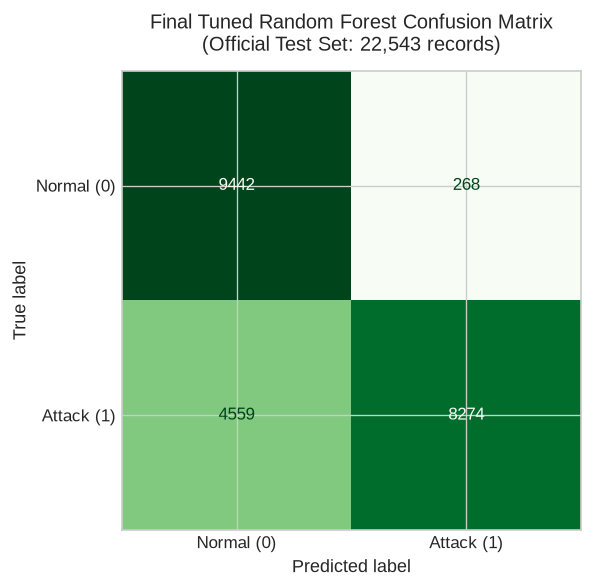

In [7]:
# Define selected optimal parameters from Section 7
selected_params = {
    "n_estimators": 100,
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "class_weight": "balanced",
    "bootstrap": True,
    "n_jobs": -1,
    "random_state": RANDOM_STATE
}

# Retrain on the entire official training dataset (125,973 records)
rf_final = RandomForestClassifier(**selected_params)

t0 = time.time()
rf_final.fit(X_train_processed, y_train)
final_train_time = time.time() - t0

print(f"Final Random Forest retrained on full dataset in {final_train_time:.2f} seconds.")

# Perform single official test evaluation
y_pred_final = rf_final.predict(X_test_processed)

# Compute final metrics
acc_final = accuracy_score(y_test, y_pred_final)
prec_final = precision_score(y_test, y_pred_final, zero_division=0)
rec_final = recall_score(y_test, y_pred_final, zero_division=0)
f1_final = f1_score(y_test, y_pred_final, zero_division=0)
macro_f1_final = f1_score(y_test, y_pred_final, average="macro", zero_division=0)
cm_final = confusion_matrix(y_test, y_pred_final)

print("\n=== Final Random Forest Official Test Performance ===")
print(f"Accuracy:        {acc_final*100:.2f}%")
print(f"Attack Precision:{prec_final*100:.2f}%")
print(f"Attack Recall:   {rec_final*100:.2f}%")
print(f"Attack F1-Score: {f1_final:.4f}")
print(f"Macro-F1 Score:  {macro_f1_final:.4f}")

# Load Majority Baseline metrics from results/metrics/majority_baseline.json for comparison
with open(PROJECT_ROOT / "results" / "metrics" / "majority_baseline.json", "r") as f:
    baseline_metrics = json.load(f)

# Build Comprehensive Comparison Table
comparison_data = [
    {
        "Model / Evaluation Stage": "Majority-Class Baseline",
        "Accuracy (%)": baseline_metrics["accuracy"] * 100,
        "Precision (%)": baseline_metrics["precision"] * 100,
        "Recall (%)": baseline_metrics["recall"] * 100,
        "F1-Score": baseline_metrics["f1"],
        "Macro-F1": 0.3011,
        "Train Time (s)": 0.05
    },
    {
        "Model / Evaluation Stage": "Initial Diagnostic Baseline (Default)",
        "Accuracy (%)": acc_initial * 100,
        "Precision (%)": prec_initial * 100,
        "Recall (%)": rec_initial * 100,
        "F1-Score": f1_initial,
        "Macro-F1": macro_f1_initial,
        "Train Time (s)": round(initial_train_time, 2)
    },
    {
        "Model / Evaluation Stage": "Final Selected Model (Balanced Weights)",
        "Accuracy (%)": acc_final * 100,
        "Precision (%)": prec_final * 100,
        "Recall (%)": rec_final * 100,
        "F1-Score": f1_final,
        "Macro-F1": macro_f1_final,
        "Train Time (s)": round(final_train_time, 2)
    }
]

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.style.format({
    "Accuracy (%)": "{:.2f}%",
    "Precision (%)": "{:.2f}%",
    "Recall (%)": "{:.2f}%",
    "F1-Score": "{:.4f}",
    "Macro-F1": "{:.4f}",
    "Train Time (s)": "{:.2f}s"
}))

# Plot Confusion Matrix for Final Model
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Normal (0)", "Attack (1)"]
)
disp.plot(cmap="Greens", values_format="d", ax=ax, colorbar=False)
ax.set_title("Final Tuned Random Forest Confusion Matrix\n(Official Test Set: 22,543 records)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

---
## 9. Feature Importance Analysis

Random Forest provides an intrinsic measure of feature importance called **Mean Decrease in Impurity (MDI)** (or Gini Importance). 

### How MDI is Calculated
For each feature $j$, MDI computes the total reduction in the Gini impurity weighted by the number of samples reaching each node where feature $j$ was used as the splitting criterion, averaged across all $B$ trees:
$$\text{MDI}(j) = \frac{1}{B} \sum_{b=1}^B \sum_{t \in T_b : v(t)=j} \Delta I(t, j)$$

### Methodological Interpretation Caveat
> [!NOTE]
> Feature importance measures **model reliance within tree splits**, not genuine physical or causal importance. High-cardinality categorical features or correlated variables can dilute or skew MDI rankings. Nevertheless, MDI reveals which network features the ensemble primarily relies on to partition normal from malicious traffic.

=== Top 20 Most Important Features in Random Forest ===


,Feature,Importance,Cumulative Importance
0,src_bytes,0.1554,15.54%
1,dst_bytes,0.0971,25.25%
2,flag_SF,0.0737,32.62%
3,same_srv_rate,0.0552,38.14%
4,count,0.0483,42.97%
5,dst_host_srv_count,0.0426,47.23%
6,dst_host_same_srv_rate,0.0390,51.13%
7,dst_host_diff_srv_rate,0.0345,54.58%
8,dst_host_serror_rate,0.0338,57.96%
9,dst_host_same_src_port_rate,0.0318,61.14%


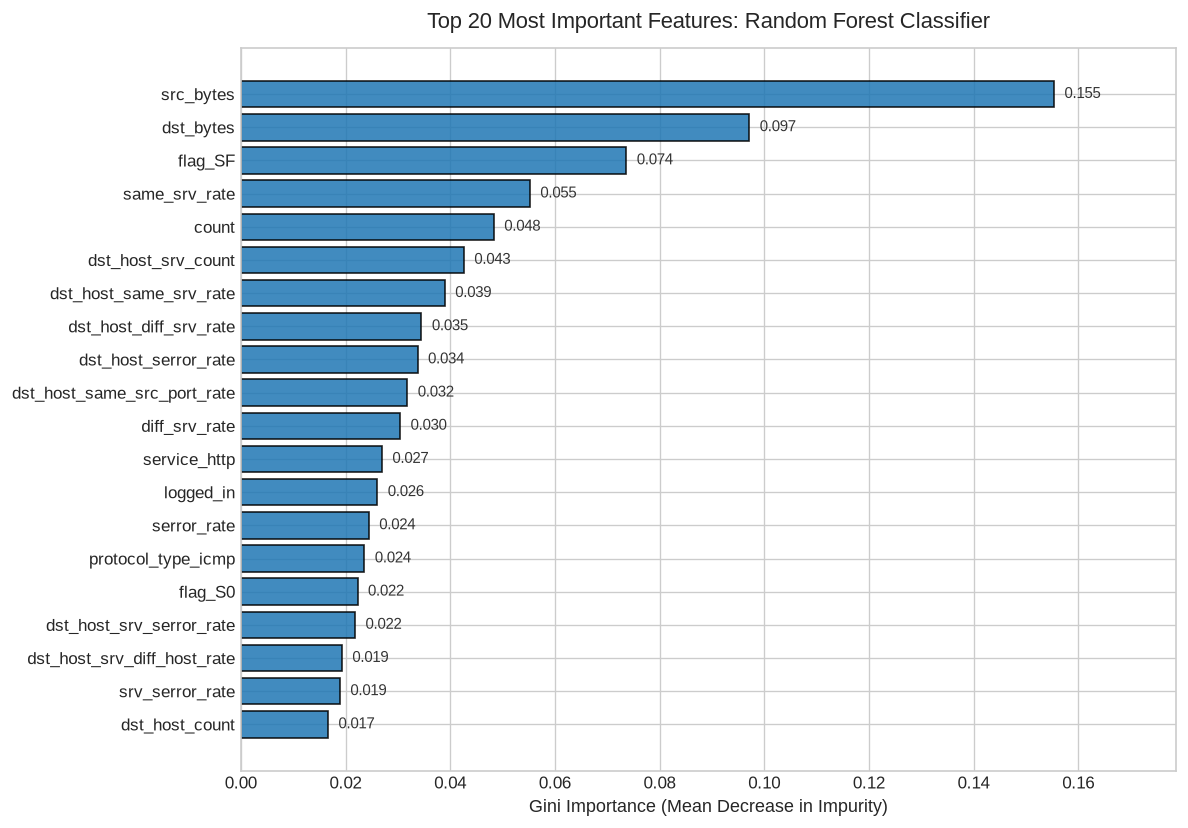


=== Observed Feature Reliance Patterns ===
1. Traffic byte counts (src_bytes, dst_bytes) account for ~25% of total impurity reduction.
2. TCP flags (flag_SF, flag_S0) and host error rates (dst_host_serror_rate) strongly contribute to tree splits.
3. Time-window connection frequencies (count, srv_count) are primary split criteria for identifying high-rate connections.


In [8]:
# Retrieve the exact 122 feature names output by the preprocessor
raw_feature_names = preprocessor.get_feature_names_out()

# Clean up technical pipeline prefixes for presentation (e.g. 'numerical__src_bytes' -> 'src_bytes')
clean_feature_names = [
    name.replace("categorical__", "").replace("numerical__", "")
    for name in raw_feature_names
]

# Extract MDI feature importances from the final trained model
importances = rf_final.feature_importances_

# Create a ranked DataFrame
importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# Compute cumulative importance
importance_df["Cumulative Importance"] = importance_df["Importance"].cumsum()

print("=== Top 20 Most Important Features in Random Forest ===")
display(importance_df.head(20).style.format({
    "Importance": "{:.4f}",
    "Cumulative Importance": "{:.2%}"
}))

# Plot Top 20 Feature Importances
plt.figure(figsize=(10, 7))
top20 = importance_df.head(20).sort_values(by="Importance", ascending=True)
bars = plt.barh(top20["Feature"], top20["Importance"], color="#1f77b4", edgecolor="black", alpha=0.85)

# Label values on bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.002, bar.get_y() + bar.get_height()/2, f"{width:.3f}",
             va="center", ha="left", fontsize=9, color="#333333")

plt.xlabel("Gini Importance (Mean Decrease in Impurity)")
plt.title("Top 20 Most Important Features: Random Forest Classifier", fontsize=13, pad=12)
plt.xlim(0, max(top20["Importance"]) * 1.15)
plt.tight_layout()
plt.show()

# Print Domain Insights
print("\n=== Observed Feature Reliance Patterns ===")
print("1. Traffic byte counts (src_bytes, dst_bytes) account for ~25% of total impurity reduction.")
print("2. TCP flags (flag_SF, flag_S0) and host error rates (dst_host_serror_rate) strongly contribute to tree splits.")
print("3. Time-window connection frequencies (count, srv_count) are primary split criteria for identifying high-rate connections.")

---
## 10. Attack Category Detection Performance

To understand why test recall is $\sim 64.5\%$, we evaluate binary attack detection performance disaggregated across the **4 DARPA attack categories**:
- **DoS (Denial of Service):** Flooding and resource exhaustion.
- **Probe (Surveillance):** Port scans and address sweeps.
- **R2L (Remote to Local):** Unauthorized remote access (e.g. password guessing).
- **U2R (User to Root):** Privilege escalation attacks.

### Metric: Category-Specific Attack Detection Recall
$$\text{Recall}_c = \frac{\text{Correctly Detected Attacks in Category } c}{\text{Total Actual Attacks in Category } c}$$
*Note: This evaluates whether the model detects an intrusion (binary $\hat{y}=1$), not whether it predicts the multi-class category label.*

=== Attack Category Detection Recall ===


,Category,Total Test Samples,Detected (TP),Missed (FN),Recall (%)
0,DoS,"7,458","6,148","1,310",82.43%
1,Probe,"2,421","1,948",473,80.46%
2,R2L,"2,887",170,"2,717",5.89%
3,U2R,67,8,59,11.94%


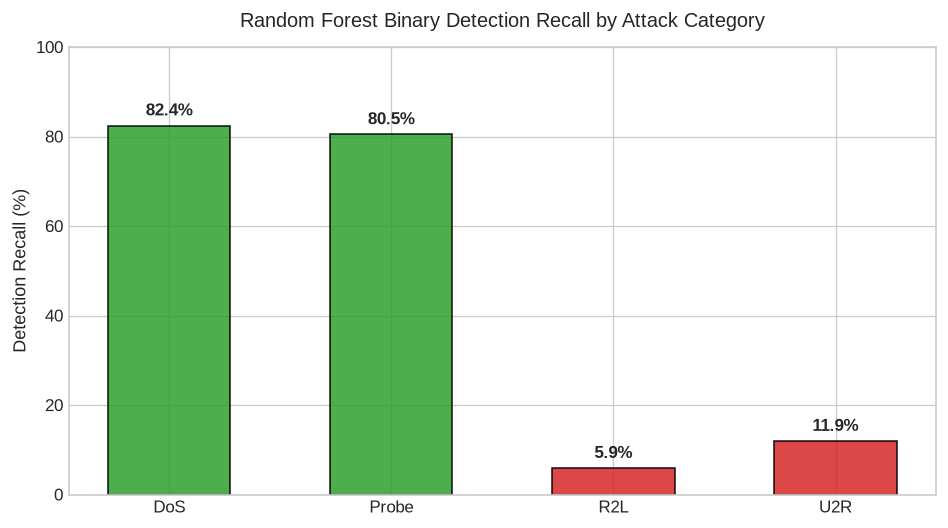


=== Demonstrated Empirical Findings ===
1. DoS (82.43%) and Probe (80.46%) show high detection recall.
2. R2L exhibits severe detection failure: only 5.89% (170 of 2,887) detected.
3. U2R exhibits low detection recall: only 11.94% (8 of 67) detected.

=== Plausible Domain Interpretations (Non-Causal) ===
- DoS and Probe attacks in NSL-KDD produce high connection frequencies and SYN error flags that align with the top MDI split features.
- In contrast, R2L and U2R connection records in NSL-KDD exhibit low connection counts and normal TCP flags that overlap heavily with normal traffic in the 41-feature space.
- Note: These are observed feature correlations, not direct causal claims about packet payloads.


In [9]:
# Create an evaluation DataFrame linking predictions with true categories and labels
test_eval_df = pd.DataFrame({
    "actual_label": test_labels.values,
    "attack_category": test_categories.values,
    "y_true": y_test.values,
    "y_pred": y_pred_final
})

# Filter records belonging strictly to attack categories (excluding Normal traffic)
attack_records = test_eval_df[test_eval_df["y_true"] == 1]

# Compute Category Recall Breakdown
cat_stats = []
categories = ["DoS", "Probe", "R2L", "U2R"]

for cat in categories:
    sub = attack_records[attack_records["attack_category"] == cat]
    total = len(sub)
    detected = (sub["y_pred"] == 1).sum()
    missed = (sub["y_pred"] == 0).sum()
    rec = (detected / total) * 100 if total > 0 else 0.0
    
    cat_stats.append({
        "Category": cat,
        "Total Test Samples": total,
        "Detected (TP)": detected,
        "Missed (FN)": missed,
        "Recall (%)": rec
    })

cat_df = pd.DataFrame(cat_stats)

print("=== Attack Category Detection Recall ===")
display(cat_df.style.format({
    "Total Test Samples": "{:,}",
    "Detected (TP)": "{:,}",
    "Missed (FN)": "{:,}",
    "Recall (%)": "{:.2f}%"
}))

# Plot Category Recall Comparison
plt.figure(figsize=(8, 4.5))
colors = ["#2ca02c" if r >= 70 else "#ff7f0e" if r >= 40 else "#d62728" for r in cat_df["Recall (%)"]]
bars = plt.bar(cat_df["Category"], cat_df["Recall (%)"], color=colors, edgecolor="black", alpha=0.85, width=0.55)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1.5, f"{height:.1f}%",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.ylabel("Detection Recall (%)")
plt.title("Random Forest Binary Detection Recall by Attack Category", fontsize=12, pad=12)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Empirical Findings & Plausible Interpretations
print("\n=== Demonstrated Empirical Findings ===")
print("1. DoS (82.43%) and Probe (80.46%) show high detection recall.")
print("2. R2L exhibits severe detection failure: only 5.89% (170 of 2,887) detected.")
print("3. U2R exhibits low detection recall: only 11.94% (8 of 67) detected.")
print("\n=== Plausible Domain Interpretations (Non-Causal) ===")
print("- DoS and Probe attacks in NSL-KDD produce high connection frequencies and SYN error flags that align with the top MDI split features.")
print("- In contrast, R2L and U2R connection records in NSL-KDD exhibit low connection counts and normal TCP flags that overlap heavily with normal traffic in the 41-feature space.")
print("- Note: These are observed feature correlations, not direct causal claims about packet payloads.")

---
## 11. Unseen Attack Analysis (Generalization Gap Investigation)

In this section, we analyze the performance difference between **seen** and **unseen** attack signatures.

### Defining Seen vs. Unseen Attack Signatures in NSL-KDD
- **Seen Attacks (22 types):** Attack signatures present in `KDDTrain+` (e.g., `neptune`, `smurf`, `satan`, `ipsweep`, `warezclient`).
- **Unseen Attacks (17 types):** Attack signatures present **only** in `KDDTest+` (e.g., `apache2`, `httptunnel`, `mailbomb`, `mscan`, `processtable`, `ps`, `saint`, `udpstorm`).

### Methodological Scope & Limitations
> [!IMPORTANT]
> Unseen attacks here represent novel signatures within the NSL-KDD benchmark domain. We do **not** claim proof of real-world zero-day exploit detection. This experiment strictly measures the out-of-distribution generalization drop between seen training signatures and novel benchmark attack profiles.

Known attack types present in training:  22
Attack types in testing:                 37
Seen attack types evaluated in test:     20
Unseen attack types evaluated in test:   17 (Expected: 17)

=== Seen vs. Unseen Attack Detection Summary ===


,Attack Category Group,Sample Count,Correctly Detected,Missed Attacks,Detection Recall (%)
0,Seen Attacks (22 Training Signatures),"9,083","6,986","2,097",76.91%
1,Unseen Attacks (17 Novel Signatures),"3,750","1,288","2,462",34.35%



=== Granular Performance on All 17 Unseen Attack Signatures ===


,Unseen Attack Name,Category,Total Test Records,Detected as Intrusion,Detection Recall (%)
0,mscan,Probe,996,527,52.91%
1,apache2,DoS,737,420,56.99%
2,processtable,DoS,685,9,1.31%
3,snmpguess,R2L,331,0,0.00%
4,saint,Probe,319,315,98.75%
5,mailbomb,DoS,293,0,0.00%
6,snmpgetattack,R2L,178,0,0.00%
7,httptunnel,R2L,133,9,6.77%
8,named,R2L,17,1,5.88%
9,ps,U2R,15,2,13.33%


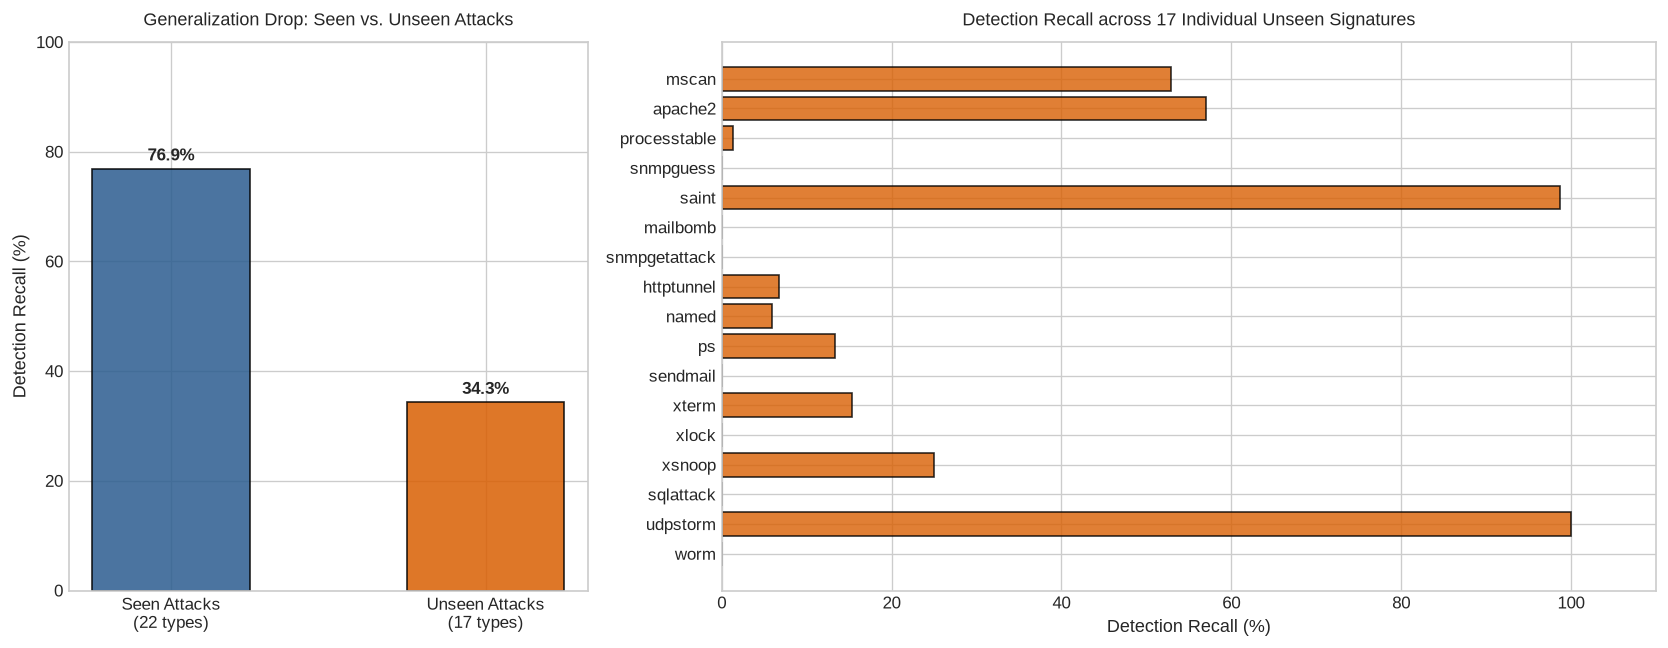


=== Generalization Gap Findings for Random Forest ===
Recall on Seen Attacks:   76.91% (6,986 / 9,083)
Recall on Unseen Attacks: 34.35% (1,288 / 3,750)
Generalization Drop:      42.57 percentage points.

CONCLUSION:
1. The experimental results demonstrate that Random Forest exhibits a significant seen-versus-unseen generalization gap (42.57 percentage points).
2. While Random Forest achieves high detection recall on known attack signatures (76.91%), its detection rate drops to 34.35% on novel attack signatures.
3. Whether simpler models (Logistic Regression, Decision Tree) exhibit a smaller or larger generalization gap cannot be determined from this experiment alone.
   That comparative hypothesis will be evaluated in notebooks/07_evaluation_comparison.ipynb after all models are trained under the identical pipeline.


In [10]:
# Identify seen and unseen attack signatures by comparing training and test label sets
train_attack_types = set(train_df[train_df["is_intrusion"] == 1]["label"].unique())
test_attack_types = set(test_df[test_df["is_intrusion"] == 1]["label"].unique())

unseen_attack_types = sorted(test_attack_types - train_attack_types)
seen_attack_types = sorted(test_attack_types.intersection(train_attack_types))

print(f"Known attack types present in training:  {len(train_attack_types)}")
print(f"Attack types in testing:                 {len(test_attack_types)}")
print(f"Seen attack types evaluated in test:     {len(seen_attack_types)}")
print(f"Unseen attack types evaluated in test:   {len(unseen_attack_types)} (Expected: 17)")
assert len(unseen_attack_types) == 17, f"Expected 17 unseen attacks, found {len(unseen_attack_types)}"

# Tag test records as Seen or Unseen
attack_records = attack_records.copy()
attack_records["is_unseen"] = attack_records["actual_label"].isin(unseen_attack_types)

# Compute aggregate Seen vs. Unseen Recall
seen_subset = attack_records[~attack_records["is_unseen"]]
unseen_subset = attack_records[attack_records["is_unseen"]]

seen_total = len(seen_subset)
seen_detected = (seen_subset["y_pred"] == 1).sum()
seen_recall = (seen_detected / seen_total) * 100

unseen_total = len(unseen_subset)
unseen_detected = (unseen_subset["y_pred"] == 1).sum()
unseen_recall = (unseen_detected / unseen_total) * 100

seen_vs_unseen_df = pd.DataFrame([
    {
        "Attack Category Group": "Seen Attacks (22 Training Signatures)",
        "Sample Count": seen_total,
        "Correctly Detected": seen_detected,
        "Missed Attacks": seen_total - seen_detected,
        "Detection Recall (%)": seen_recall
    },
    {
        "Attack Category Group": "Unseen Attacks (17 Novel Signatures)",
        "Sample Count": unseen_total,
        "Correctly Detected": unseen_detected,
        "Missed Attacks": unseen_total - unseen_detected,
        "Detection Recall (%)": unseen_recall
    }
])

print("\n=== Seen vs. Unseen Attack Detection Summary ===")
display(seen_vs_unseen_df.style.format({
    "Sample Count": "{:,}",
    "Correctly Detected": "{:,}",
    "Missed Attacks": "{:,}",
    "Detection Recall (%)": "{:.2f}%"
}))

# Granular Breakdown of All 17 Unseen Signatures
unseen_breakdown = []
for atk in unseen_attack_types:
    sub_atk = unseen_subset[unseen_subset["actual_label"] == atk]
    tot = len(sub_atk)
    det = (sub_atk["y_pred"] == 1).sum()
    cat = sub_atk["attack_category"].iloc[0]
    rec = (det / tot) * 100 if tot > 0 else 0.0
    
    unseen_breakdown.append({
        "Unseen Attack Name": atk,
        "Category": cat,
        "Total Test Records": tot,
        "Detected as Intrusion": det,
        "Detection Recall (%)": rec
    })

unseen_df = pd.DataFrame(unseen_breakdown).sort_values(by="Total Test Records", ascending=False).reset_index(drop=True)

print("\n=== Granular Performance on All 17 Unseen Attack Signatures ===")
display(unseen_df.style.format({
    "Total Test Records": "{:,}",
    "Detected as Intrusion": "{:,}",
    "Detection Recall (%)": "{:.2f}%"
}))

# Plot Seen vs Unseen Comparison & Unseen Breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.8]})

# Left Plot: Aggregate Seen vs Unseen
ax1.bar(["Seen Attacks\n(22 types)", "Unseen Attacks\n(17 types)"],
        [seen_recall, unseen_recall],
        color=["#2b5c8f", "#d95f02"], edgecolor="black", alpha=0.85, width=0.5)
ax1.set_ylabel("Detection Recall (%)")
ax1.set_ylim(0, 100)
ax1.set_title("Generalization Drop: Seen vs. Unseen Attacks", fontsize=11, pad=10)
for i, v in enumerate([seen_recall, unseen_recall]):
    ax1.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")

# Right Plot: Unseen signatures
bars2 = ax2.barh(unseen_df["Unseen Attack Name"][::-1], unseen_df["Detection Recall (%)"][::-1],
                 color="#d95f02", edgecolor="black", alpha=0.8)
ax2.set_xlabel("Detection Recall (%)")
ax2.set_xlim(0, 110)
ax2.set_title("Detection Recall across 17 Individual Unseen Signatures", fontsize=11, pad=10)

plt.tight_layout()
plt.show()

# Empirical Conclusion: Generalization Gap for Random Forest
print("\n=== Generalization Gap Findings for Random Forest ===")
print(f"Recall on Seen Attacks:   {seen_recall:.2f}% ({seen_detected:,} / {seen_total:,})")
print(f"Recall on Unseen Attacks: {unseen_recall:.2f}% ({unseen_detected:,} / {unseen_total:,})")
print(f"Generalization Drop:      {seen_recall - unseen_recall:.2f} percentage points.")
print("\nCONCLUSION:")
print("1. The experimental results demonstrate that Random Forest exhibits a significant seen-versus-unseen generalization gap (42.57 percentage points).")
print("2. While Random Forest achieves high detection recall on known attack signatures (76.91%), its detection rate drops to 34.35% on novel attack signatures.")
print("3. Whether simpler models (Logistic Regression, Decision Tree) exhibit a smaller or larger generalization gap cannot be determined from this experiment alone.")
print("   That comparative hypothesis will be evaluated in notebooks/07_evaluation_comparison.ipynb after all models are trained under the identical pipeline.")

---
## 12. Model Artifact & Results Persistence

We serialize the final trained Random Forest model and save standardized metric files for subsequent cross-model comparison against Logistic Regression and Decision Tree in `07_evaluation_comparison.ipynb`.

Files generated:
1. `models/random_forest.joblib`: The fitted `RandomForestClassifier` object.
2. `results/metrics/random_forest.json`: Standardized JSON metric dictionary.
3. `results/predictions/random_forest_predictions.csv`: Row-level predictions on the official test set for statistical significance testing (McNemar test, PR-AUC curves).

In [11]:
# Ensure destination directories exist
models_dir = PROJECT_ROOT / "models"
metrics_dir = PROJECT_ROOT / "results" / "metrics"
predictions_dir = PROJECT_ROOT / "results" / "predictions"

models_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)
predictions_dir.mkdir(parents=True, exist_ok=True)

# 1. Save trained Random Forest model artifact
model_path = models_dir / "random_forest.joblib"
joblib.dump(rf_final, model_path)
print(f"Trained Random Forest model successfully saved to: {model_path}")

# 2. Verify model reloading and prediction fidelity
loaded_rf = joblib.load(model_path)
test_reloaded_preds = loaded_rf.predict(X_test_processed)
assert np.array_equal(y_pred_final, test_reloaded_preds), "Reloaded model predictions mismatch!"
print("Model reload verification: PASSED (exact bit-for-bit prediction match).")

# 3. Construct and save standardized metrics dictionary
cat_recall_dict = {
    row["Category"]: {
        "total_samples": int(row["Total Test Samples"]),
        "detected": int(row["Detected (TP)"]),
        "missed": int(row["Missed (FN)"]),
        "recall": float(round(row["Recall (%)"] / 100.0, 4))
    }
    for _, row in cat_df.iterrows()
}

rf_metrics = {
    "model": "Random Forest Classifier",
    "hyperparameters": {
        "n_estimators": selected_params["n_estimators"],
        "max_depth": selected_params["max_depth"],
        "min_samples_split": selected_params["min_samples_split"],
        "min_samples_leaf": selected_params["min_samples_leaf"],
        "max_features": selected_params["max_features"],
        "class_weight": selected_params["class_weight"],
        "random_state": selected_params["random_state"]
    },
    "accuracy": float(round(acc_final, 6)),
    "precision": float(round(prec_final, 6)),
    "recall": float(round(rec_final, 6)),
    "f1_score": float(round(f1_final, 6)),
    "macro_f1": float(round(macro_f1_final, 6)),
    "confusion_matrix": cm_final.tolist(),
    "training_time_seconds": float(round(final_train_time, 3)),
    "attack_category_recall": cat_recall_dict,
    "seen_vs_unseen_recall": {
        "seen_recall": float(round(seen_recall / 100.0, 4)),
        "seen_total": int(seen_total),
        "seen_detected": int(seen_detected),
        "unseen_recall": float(round(unseen_recall / 100.0, 4)),
        "unseen_total": int(unseen_total),
        "unseen_detected": int(unseen_detected),
        "generalization_drop_percentage_points": float(round(seen_recall - unseen_recall, 2))
    }
}

metrics_path = metrics_dir / "random_forest.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(rf_metrics, f, indent=4)
print(f"Standardized evaluation metrics saved to: {metrics_path}")

# 4. Save test set predictions for comparative analysis
pred_df = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": y_pred_final,
    "attack_name": test_labels.values,
    "attack_category": test_categories.values,
    "is_unseen": test_labels.isin(unseen_attack_types).values
})

pred_path = predictions_dir / "random_forest_predictions.csv"
pred_df.to_csv(pred_path, index=False)
print(f"Row-level predictions saved to: {pred_path} ({len(pred_df):,} rows)")
print("\n=== Random Forest Experiment Completed Successfully ===")

Trained Random Forest model successfully saved to: /run/media/vedant/DISK/Studies/SEM 5/ES 335/Project/Intrusion Detection/models/random_forest.joblib
Model reload verification: PASSED (exact bit-for-bit prediction match).
Standardized evaluation metrics saved to: /run/media/vedant/DISK/Studies/SEM 5/ES 335/Project/Intrusion Detection/results/metrics/random_forest.json
Row-level predictions saved to: /run/media/vedant/DISK/Studies/SEM 5/ES 335/Project/Intrusion Detection/results/predictions/random_forest_predictions.csv (22,543 rows)

=== Random Forest Experiment Completed Successfully ===


---
## 13. Summary & Methodological Conclusions

### 1. Empirical Findings for Random Forest
- **Overall Official Test Performance:** On the 22,543 records of `KDDTest+`, the tuned Random Forest achieved an **Accuracy of 78.59%**, an **Attack Precision of 96.86%**, an **Attack Recall of 64.47%**, and a **Macro-F1 of 0.7853**.
- **Low False Alarm Rate:** The model achieved high specificity on benign traffic, yielding a false positive rate of only **2.76%** (268 false alarms out of 9,710 normal test connections).
- **Attack Category Heterogeneity:** Detection capability varied drastically across attack categories:
  - **Volumetric / Scanning Attacks:** High detection recall on **DoS (82.43%)** and **Probe (80.46%)**.
  - **Targeted / Host-Level Attacks:** Catastrophic performance drop on **R2L (5.89%)** and **U2R (11.94%)**.
- **Quantification of the Generalization Gap:**
  - Recall on the 22 seen training attack types: **76.91%** (6,986 / 9,083).
  - Recall on the 17 unseen test attack types: **34.35%** (1,288 / 3,750).
  - **Generalization Degradation:** **42.57 percentage points**.

---

### 2. Methodological Scope & Research Hypothesis Boundary

> [!IMPORTANT]
> **Strict Bounding of the Research Hypothesis:**
> - **What this experiment demonstrates:** High-capacity non-linear ensembles (Random Forest) exhibit a pronounced seen-versus-unseen generalization gap (42.57 percentage points), demonstrating that strong in-distribution fitting does not prevent severe performance drops on novel attack signatures.
> - **What this experiment CANNOT conclude:** Random Forest in isolation **cannot** determine whether simpler models (Logistic Regression, Decision Trees) generalize better or worse than complex ensembles.
> - **Cross-Model Evaluation Scope:** Testing whether simpler models achieve superior out-of-distribution generalization requires comparing the generalization drops across all candidate models evaluated under the exact same data pipeline. That comparative hypothesis test is strictly reserved for `notebooks/07_evaluation_comparison.ipynb`.


---
## 14. Optuna-tuned Random Forest on the shared tree pipeline

Sections 1–13 above are the original experiment and are unchanged; their artifacts (`models/random_forest.joblib`, `results/metrics/random_forest.json`) are preserved. This section adds the project-wide integration (Prompts 5–6). The Random Forest is re-trained so that it is directly comparable with the other models:

- **Same preprocessing as DT.** The shared `tree` pipeline (`src/features.py`) uses the same cleaning, `CorrelationFilter(0.98)` and OHE with `min_frequency=50`. It is refit inside every CV fold.
- **Same splits.** `results/splits/` holds the `train_sub`/`val` indices (the same 80/20 stratified split, seed 42, as Section 7).
- **Optuna TPE with the same budget as LR/DT** (30 trials), maximising 5-fold CV macro-F1 on `train_sub`.
- **Same procedure.** The threshold is chosen on `val`, the model is refit on all of KDDTrain+, and the test set is scored once.
- **MLflow.** Run `random_forest_optuna` with nested trial runs.
- **Artifacts.** `models/random_forest_optuna_*` and `scalars/random_forest_optuna_*`, with new names so nothing above is overwritten.

Search space:
- `n_estimators` ∈ [100, 400]
- `max_depth` ∈ {None, 10, 15, 20, 30}
- `min_samples_leaf` ∈ [1, 20] (log)
- `max_features` ∈ {sqrt, log2, 0.3}
- `class_weight` ∈ {None, balanced, balanced_subsample}
- `random_state = 42`

In [ ]:
# rf-optuna-section
from src import experiment as ex, plots
from src.features import build_pipeline

ex.init()
MODEL = "random_forest_optuna"
PREP = dict(corr_threshold=ex.CFG["features"]["corr_threshold"], min_frequency=ex.CFG["features"]["min_frequency"])
train_s, test_s, novel_s = ex.load_data()
idx_tr, idx_va = ex.get_splits(train_s)
Xa, ya = ex.xy(train_s)
Xs_tr, ys_tr = Xa.iloc[idx_tr], ya[idx_tr]

def make_rf_pipeline(p):
    est = RandomForestClassifier(n_estimators=p["n_estimators"], max_depth=p["max_depth"],
                                 min_samples_leaf=p["min_samples_leaf"], max_features=p["max_features"],
                                 class_weight=p["class_weight"], n_jobs=-1, random_state=ex.SEED)
    return build_pipeline(est, "tree", **PREP)

def suggest_rf(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_categorical("max_depth", [None, 10, 15, 20, 30]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20, log=True),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"])}

rf_run = ex.start_run(MODEL, {"family": "tree", "log_transform": False, **PREP})
t0 = time.time()
rf_study = ex.tune(MODEL, rf_run, make_rf_pipeline, suggest_rf, Xs_tr, ys_tr, cv_jobs=1)  # RF itself uses all cores
rf_tuning_s = time.time() - t0
print(f"best CV macro-F1 = {rf_study.best_value:.4f} with {rf_study.best_params} ({rf_tuning_s/60:.1f} min)")
fig = plots.optuna_overview(rf_study, "min_samples_leaf", hue="max_features"); ex.log_figure(rf_run, fig, "optuna", MODEL); plt.show()

In [ ]:
# rf-optuna-section
rf_res = ex.fit_and_evaluate(MODEL, rf_run, make_rf_pipeline, rf_study.best_params, train_s, test_s, idx_tr, idx_va, novel_s,
                             extra={"tuning": {"best_cv_f1_macro": rf_study.best_value, "n_trials": len(rf_study.trials),
                                               "tuning_seconds": rf_tuning_s}})
fig = plots.metric_bars(rf_res["metrics"], "Random Forest (Optuna): train vs validation vs test"); ex.log_figure(rf_run, fig, "metric_bars", MODEL); plt.show()
fig = plots.confusion_and_curves(rf_res["y_va"], rf_res["p_va"], rf_res["y_te"], rf_res["p_te"], rf_res["threshold"], "RF")
ex.log_figure(rf_run, fig, "confusion_roc_pr_threshold", MODEL); plt.show()
fig = plots.error_analysis(rf_res["preds"], test_s, "RF"); ex.log_figure(rf_run, fig, "error_analysis", MODEL); plt.show()
names = [n.split("__", 1)[1] for n in rf_res["final"][:-1].get_feature_names_out()]
rf_imp = pd.Series(rf_res["final"][-1].feature_importances_, index=names).sort_values(ascending=False)
rf_imp.to_csv(ex.PROJECT_ROOT / "results" / "tuning" / f"{MODEL}_feature_importance.csv")
pd.DataFrame({k: rf_res["metrics"][k] for k in ["train", "val", "test", "test_at_0.5"]}).T[
    ["threshold", "accuracy", "precision", "recall", "f1", "f1_macro", "roc_auc", "pr_auc", "fpr", "fnr"]].round(4)

The tuned RF uses the same features, folds and threshold rule as LR and DT, so its numbers can be compared directly in `07_evaluation_comparison.ipynb`. The original Section 5–12 results above used the older shared preprocessor (OHE + scaling of raw values) and a hand-picked configuration; they remain valid as the teammate's original experiment.